In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt

from config import Config as c

In [23]:
df_subjects = pd.read_csv(c.CSV_DIR / 'subjects.csv', index_col=0)
df_subjects

,record_start,segment_id,segment_time,master_id,class
subject_id,,,,,
48480,2116-05-04 17:50:00,3876369_0016,49774.000,p048480-2116-05-04-17-50,control
63646,2177-05-29 11:39:00,3089087_0007,42791.000,p063646-2177-05-29-11-39,control
64485,2168-10-15 13:24:00,3625999_0008,65231.000,p064485-2168-10-15-13-24,control
64916,2102-02-22 16:40:00,3181603_0003,39206.000,p064916-2102-02-22-16-40,control
66682,2130-05-10 12:40:00,3549618_0015,39738.000,p066682-2130-05-10-12-40,control
67763,2163-09-18 02:36:00,3295996_0009,36611.000,p067763-2163-09-18-02-36,control
69006,2174-02-05 18:35:00,3098482_0012,55723.000,p069006-2174-02-05-18-35,control
76178,2109-12-20 20:52:00,3045819_0010,42634.000,p076178-2109-12-20-20-52,control
76237,2128-09-16 10:40:00,3670140_0003,128277.000,p076237-2128-09-16-10-40,control


In [18]:
df_features_ppg = pd.read_csv(c.CSV_DIR / 'features_ppg.csv', index_col=0)
df_features_ppg

,a_s,a_d,t_pw,ri,ai,t_dt,t_ct,r_b_a,r_c_a,r_d_a,r_e_a,r_b_c_d_e_a,r_b_e_a,r_b_c_d_a
subject_id,,,,,,,,,,,,,,
48480,0.361873,0.031386,38.0,0.086732,0.913268,59.0,32.0,-1.085609,-0.567642,-0.567642,0.317664,-0.267990,-1.403273,0.049674
63646,1.491539,0.779208,45.0,0.522419,0.477581,25.0,36.0,-0.781589,-0.715132,-0.715132,0.242890,0.405785,-1.024479,0.648675
64485,0.089306,0.064812,68.0,0.725731,0.274269,27.0,41.0,-0.705074,-0.270410,-0.280023,0.079289,-0.233929,-0.784363,-0.154641
64916,1.894331,1.072385,37.0,0.566102,0.433898,18.0,31.0,-0.702971,-0.560234,-0.660374,0.301680,0.215957,-1.004651,0.517637
66682,1.816996,0.193730,40.0,0.106621,0.893379,64.0,28.0,-0.914228,-0.105199,-0.105199,0.229847,-0.933677,-1.144075,-0.703830
67763,1.796338,0.200030,33.0,0.111354,0.888646,55.0,26.0,-1.079361,-0.023074,-0.023074,0.331617,-1.364831,-1.410978,-1.033214
69006,1.831890,0.936452,44.0,0.511194,0.488806,23.0,36.0,-0.713629,-0.586352,-0.668427,0.328535,0.212616,-1.042164,0.541151
76178,0.225135,0.092970,48.0,0.412953,0.587047,40.0,31.0,-0.851224,-0.339708,-0.339708,0.215687,-0.387496,-1.066911,-0.171809
76237,1.769964,-0.017138,34.0,-0.009683,1.009683,59.0,24.0,-1.084380,-0.066254,-0.066254,0.230860,-1.182733,-1.315240,-0.951873


In [19]:
df_features_ecg_abp = pd.read_csv(c.CSV_DIR / 'features_ecg+abp.csv', index_col=0)
df_features_ecg_abp

,rri_fft_vlf,rri_fft_lf,rri_fft_hf,rri_fft_r_lf_hf,rri_welch_vlf,rri_welch_lf,rri_welch_hf,rri_welch_r_lf_hf,rri_ar_vlf,rri_ar_lf,...,dbp_fft_hf,dbp_fft_r_lf_hf,dbp_welch_vlf,dbp_welch_lf,dbp_welch_hf,dbp_welch_r_lf_hf,dbp_ar_vlf,dbp_ar_lf,dbp_ar_hf,dbp_ar_r_lf_hf
subject_id,,,,,,,,,,,,,,,,,,,,,
8061,0.67156,0.13683,0.19161,0.7141,0.72648,0.12093,0.15259,0.7925,0.75089,0.09729,...,0.72307,0.1821,0.15352,0.14478,0.70170,0.2063,0.19394,0.14665,0.65941,0.2224
9124,0.16993,0.36460,0.46546,0.7833,0.17283,0.41495,0.41222,1.0066,0.18240,0.41085,...,0.54786,0.4252,0.18140,0.25180,0.56680,0.4443,0.17580,0.25276,0.57144,0.4423
10842,0.36680,0.09315,0.54005,0.1725,0.37618,0.10877,0.51505,0.2112,0.38335,0.12784,...,0.23903,0.9444,0.52825,0.18896,0.28280,0.6682,0.57122,0.16364,0.26514,0.6172
40435,0.14191,0.75846,0.09963,7.6125,0.19227,0.69417,0.11357,6.1124,0.17835,0.68437,...,0.45055,0.9081,0.16103,0.33963,0.49934,0.6802,0.20251,0.28758,0.50991,0.5640
40724,0.82379,0.10562,0.07059,1.4961,0.75066,0.15561,0.09372,1.6603,0.69858,0.19158,...,0.04649,0.4174,0.91500,0.02933,0.05567,0.5268,0.90972,0.03879,0.05149,0.7534
47874,0.73180,0.07122,0.19698,0.3616,0.66881,0.09034,0.24085,0.3751,0.71201,0.09306,...,0.75026,0.0773,0.21674,0.05889,0.72437,0.0813,0.24490,0.05801,0.69709,0.0832
48480,0.80334,0.05011,0.14655,0.3419,0.69116,0.15080,0.15804,0.9542,0.70745,0.15664,...,0.35846,0.6249,0.33381,0.27433,0.39187,0.7001,0.36306,0.25750,0.37944,0.6786
54132,0.84993,0.12922,0.02085,6.1980,0.75478,0.22436,0.02086,10.7568,0.73010,0.24259,...,0.15683,4.0119,0.27303,0.57169,0.15528,3.6817,0.16111,0.69017,0.14872,4.6408
54586,0.38710,0.37896,0.23395,1.6198,0.48165,0.31213,0.20621,1.5136,0.50119,0.29190,...,0.33187,0.8777,0.37723,0.26807,0.35470,0.7558,0.46510,0.20971,0.32519,0.6449


In [20]:
df_features = pd.concat((df_features_ecg_abp, df_features_ppg), axis=1)
df_features

,rri_fft_vlf,rri_fft_lf,rri_fft_hf,rri_fft_r_lf_hf,rri_welch_vlf,rri_welch_lf,rri_welch_hf,rri_welch_r_lf_hf,rri_ar_vlf,rri_ar_lf,...,ai,t_dt,t_ct,r_b_a,r_c_a,r_d_a,r_e_a,r_b_c_d_e_a,r_b_e_a,r_b_c_d_a
subject_id,,,,,,,,,,,,,,,,,,,,,
8061,0.67156,0.13683,0.19161,0.7141,0.72648,0.12093,0.15259,0.7925,0.75089,0.09729,...,0.378315,28.0,33.0,-0.654194,-0.379152,-0.379152,0.172383,-0.068273,-0.826576,0.104110
9124,0.16993,0.36460,0.46546,0.7833,0.17283,0.41495,0.41222,1.0066,0.18240,0.41085,...,0.800399,41.0,23.0,-0.944670,-0.089583,-0.310002,0.454149,-0.999235,-1.398819,-0.545086
10842,0.36680,0.09315,0.54005,0.1725,0.37618,0.10877,0.51505,0.2112,0.38335,0.12784,...,0.836782,41.0,30.0,-0.720522,-0.266575,-0.348175,0.511553,-0.617325,-1.232075,-0.105771
40435,0.14191,0.75846,0.09963,7.6125,0.19227,0.69417,0.11357,6.1124,0.17835,0.68437,...,0.788814,45.0,25.0,-0.905850,-0.086865,-0.279465,0.318441,-0.857961,-1.224290,-0.539520
40724,0.82379,0.10562,0.07059,1.4961,0.75066,0.15561,0.09372,1.6603,0.69858,0.19158,...,0.668166,34.0,21.0,-1.000777,-0.088178,-0.128798,0.187363,-0.971165,-1.188141,-0.783801
47874,0.73180,0.07122,0.19698,0.3616,0.66881,0.09034,0.24085,0.3751,0.71201,0.09306,...,0.740185,35.0,32.0,-0.974908,-0.716276,-0.716276,0.237896,0.219748,-1.212804,0.457644
48480,0.80334,0.05011,0.14655,0.3419,0.69116,0.15080,0.15804,0.9542,0.70745,0.15664,...,0.913268,59.0,32.0,-1.085609,-0.567642,-0.567642,0.317664,-0.267990,-1.403273,0.049674
54132,0.84993,0.12922,0.02085,6.1980,0.75478,0.22436,0.02086,10.7568,0.73010,0.24259,...,0.659520,45.0,26.0,-0.867418,-0.171364,-0.171364,0.261073,-0.785762,-1.128491,-0.524689
54586,0.38710,0.37896,0.23395,1.6198,0.48165,0.31213,0.20621,1.5136,0.50119,0.29190,...,0.855792,53.0,22.0,-1.166580,-0.002430,-0.002430,0.343240,-1.504961,-1.509820,-1.161720


In [ ]:
selected_cols = ['rri_fft_vlf', 'rri_fft_lf', 'rri_fft_hf', 'rri_fft_r_lf_hf',
                 'dbp_fft_vlf', 'dbp_fft_lf', 'dbp_fft_hf', 'dbp_fft_r_lf_hf',
                 't_pw', 'ri', 't_ct', 'r_b_a', 'r_c_a', 'r_e_a', 'r_b_c_d_e_a']
df_selected = df_features[selected_cols]
df_selected

,rri_fft_vlf,rri_fft_lf,rri_fft_hf,rri_fft_r_lf_hf,dbp_fft_vlf,dbp_fft_lf,dbp_fft_hf,dbp_fft_r_lf_hf,t_pw,ri,t_ct,r_b_a,r_c_a,r_e_a,r_b_c_d_e_a
subject_id,,,,,,,,,,,,,,,
8061,0.67156,0.13683,0.19161,0.7141,0.14525,0.13169,0.72307,0.1821,56.0,0.621685,33.0,-0.654194,-0.379152,0.172383,-0.068273
9124,0.16993,0.36460,0.46546,0.7833,0.21920,0.23294,0.54786,0.4252,38.0,0.199601,23.0,-0.944670,-0.089583,0.454149,-0.999235
10842,0.36680,0.09315,0.54005,0.1725,0.53522,0.22574,0.23903,0.9444,39.0,0.163218,30.0,-0.720522,-0.266575,0.511553,-0.617325
40435,0.14191,0.75846,0.09963,7.6125,0.14033,0.40912,0.45055,0.9081,40.0,0.211186,25.0,-0.905850,-0.086865,0.318441,-0.857961
40724,0.82379,0.10562,0.07059,1.4961,0.93411,0.01940,0.04649,0.4174,33.0,0.331834,21.0,-1.000777,-0.088178,0.187363,-0.971165
47874,0.73180,0.07122,0.19698,0.3616,0.19177,0.05798,0.75026,0.0773,41.0,0.259815,32.0,-0.974908,-0.716276,0.237896,0.219748
48480,0.80334,0.05011,0.14655,0.3419,0.41753,0.22401,0.35846,0.6249,38.0,0.086732,32.0,-1.085609,-0.567642,0.317664,-0.267990
54132,0.84993,0.12922,0.02085,6.1980,0.21400,0.62917,0.15683,4.0119,36.0,0.340480,26.0,-0.867418,-0.171364,0.261073,-0.785762
54586,0.38710,0.37896,0.23395,1.6198,0.37686,0.29127,0.33187,0.8777,25.0,0.144208,22.0,-1.166580,-0.002430,0.343240,-1.504961


In [28]:
df = df_subjects[['class']].merge(df_selected, left_index=True, right_index=True)
df

,class,rri_fft_vlf,rri_fft_lf,rri_fft_hf,rri_fft_r_lf_hf,dbp_fft_vlf,dbp_fft_lf,dbp_fft_hf,dbp_fft_r_lf_hf,t_pw,ri,t_ct,r_b_a,r_c_a,r_e_a,r_b_c_d_e_a
subject_id,,,,,,,,,,,,,,,,
48480,control,0.80334,0.05011,0.14655,0.3419,0.41753,0.22401,0.35846,0.6249,38.0,0.086732,32.0,-1.085609,-0.567642,0.317664,-0.267990
63646,control,0.58807,0.39731,0.01462,27.1741,0.40036,0.26019,0.33945,0.7665,45.0,0.522419,36.0,-0.781589,-0.715132,0.242890,0.405785
64485,control,0.35159,0.47015,0.17826,2.6375,0.18039,0.66623,0.15338,4.3438,68.0,0.725731,41.0,-0.705074,-0.270410,0.079289,-0.233929
64916,control,0.51843,0.14541,0.33616,0.4325,0.54455,0.34776,0.10769,3.2293,37.0,0.566102,31.0,-0.702971,-0.560234,0.301680,0.215957
66682,control,0.31991,0.19194,0.48815,0.3932,0.44931,0.09754,0.45315,0.2152,40.0,0.106621,28.0,-0.914228,-0.105199,0.229847,-0.933677
67763,control,0.67651,0.11073,0.21276,0.5204,0.26928,0.46016,0.27056,1.7008,33.0,0.111354,26.0,-1.079361,-0.023074,0.331617,-1.364831
69006,control,0.42018,0.29949,0.28033,1.0683,0.39601,0.23289,0.37109,0.6276,44.0,0.511194,36.0,-0.713629,-0.586352,0.328535,0.212616
76178,control,0.56755,0.32726,0.10519,3.1110,0.53574,0.39779,0.06647,5.9845,48.0,0.412953,31.0,-0.851224,-0.339708,0.215687,-0.387496
76237,control,0.72231,0.14142,0.13627,1.0379,0.49631,0.47393,0.02976,15.9247,34.0,-0.009683,24.0,-1.084380,-0.066254,0.230860,-1.182733


/tmp/ipykernel_192517/3432336387.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  corr = df.replace({'control': 0, 'diab': 1}).infer_objects(copy=False).corr()


<Axes: >

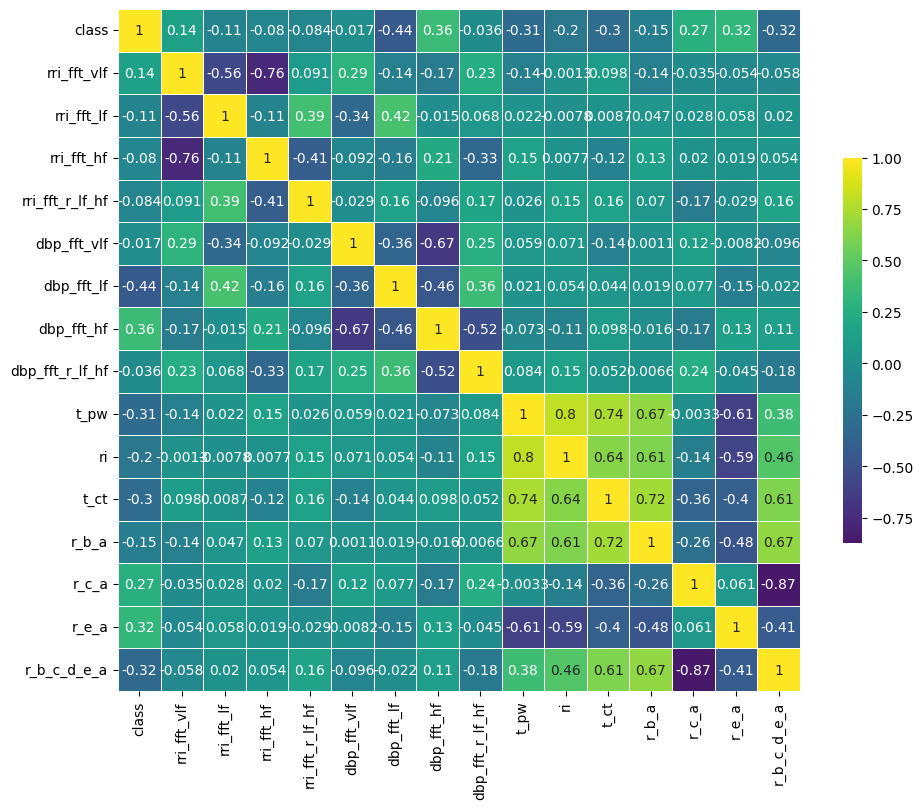

In [29]:
corr = df.replace({'control': 0, 'diab': 1}).infer_objects(copy=False).corr()
fig, ax = plt.subplots(figsize=(11, 10))
cmap = 'viridis'
# mask = np.triu(np.ones_like(corr, dtype=bool))
# sns.heatmap(corr, mask=mask, cmap=cmap, center=0, annot=True, square=True, linewidths=.5, cbar_kws={"shrink": .5})
sns.heatmap(corr, cmap=cmap, center=0, annot=True, square=True, linewidths=.5, cbar_kws={"shrink": .5})